### Comparison between SteadierCom and experimental results

NB! This notebook uses similar methods as for the "gut microbiome"-case study, but should be considered more as a sanity check. We don't have proof for the negative class here. There was no investigation on what was being consumed or produced. Production is treated as unknown, while consumption is inferred based on mutation location and expected effect.

In [47]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scipy as sp
from sklearn.metrics import confusion_matrix

import sys

sys.path.append("../functions/")
import compare_met_exp_sim.correlation as correlation
import compare_met_exp_sim.diagnostic as diagnostic
import compare_met_exp_sim.general_funcs as general_funcs
import compare_met_exp_sim.guillen2021 as guillen2021

In [48]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [49]:
signal_exp = guillen2021.load_experimental_data()
signal_exp

member       compound   
mutant_bioC  M_btn_e       -1.0
             M_cys__L_e    -0.0
             M_pnto__R_e   -0.0
mutant_bioF  M_btn_e       -1.0
             M_cys__L_e    -0.0
             M_pnto__R_e   -0.0
mutant_bioH  M_btn_e       -1.0
             M_cys__L_e    -0.0
             M_pnto__R_e   -0.0
mutant_cysW  M_btn_e       -0.0
             M_cys__L_e    -1.0
             M_pnto__R_e   -0.0
mutant_panD  M_btn_e       -0.0
             M_cys__L_e    -0.0
             M_pnto__R_e   -1.0
mutant_panZ  M_btn_e       -0.0
             M_cys__L_e    -0.0
             M_pnto__R_e   -1.0
Name: experimental, dtype: float64

In [50]:
simulation_dict = guillen2021.load_simulated_data()

# Diagnostic analysis - Binary data

In [61]:
support_df = diagnostic.identify_support(signal_exp,exp_thresh_list=[0.5])
support_df.index.names = ["role","exp_thresh"]
support_df.sort_index(ascending=False)

,,positive_support,negative_support,total,no-skill line
role,exp_thresh,,,,
receiver,0.5,6,12,18,0.333333
donor,0.5,0,18,18,0.000000


In [62]:
results_pr_auc_df = diagnostic.find_pvalues_of_PR(simulation_dict,
                                                  signal_exp,
                                                  exp_thresh_list=[0.5],
                                                  receiver_or_donor_list=["receiver"],
                                                  met_column="compound")


results_pr_auc_df_bh = results_pr_auc_df.copy()
results_pr_auc_df_bh = results_pr_auc_df_bh.join(support_df["no-skill line"])
results_pr_auc_df_bh["rank"] = results_pr_auc_df_bh["p_value"].rank()
results_pr_auc_df_bh["p-value BH critical"] = (results_pr_auc_df_bh["rank"]/results_pr_auc_df_bh.shape[0])*0.05
results_pr_auc_df_bh["pass BH test"] = results_pr_auc_df_bh["p_value"]<results_pr_auc_df_bh["p-value BH critical"]

[INFO] merge_sim_exp removes compounds not in experimental data


In [65]:
results_pr_auc_df_bh.sort_values("rank")

p_value  \
role     simulation_method condition                              agg_method metric              exp_thresh            
receiver steadiercom       SteadierCom - fixed growth             sum        frequency           0.5          0.0000   
         smetana           Smetana                                sum        mus                 0.5          0.0000   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate 0.5          0.0001   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               0.5          0.0004   
         steadiercom       SteadierCom - fixed abundance          sum        frequency           0.5          0.0026   
                           SteadierCom - fixed growth & abundance sum        frequency           0.5          0.0082   
                           SteadierCom - fixed growth             sum        frequency*mass_rate 0.5          0.1991   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 0.5          0.6828   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               0.5          1.0000   

                                                                                                             observed_auc  \
role     simulation_method condition                              agg_method metric              exp_thresh                 
receiver steadiercom       SteadierCom - fixed growth             sum        frequency           0.5             1.000000   
         smetana           Smetana                                sum        mus                 0.5             1.000000   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate 0.5             0.948413   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               0.5             0.948413   
         steadiercom       SteadierCom - fixed abundance          sum        frequency           0.5             0.794048   
                           SteadierCom - fixed growth & abundance sum        frequency           0.5             0.661905   
                           SteadierCom - fixed growth             sum        frequency*mass_rate 0.5             0.533039   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 0.5             0.352579   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               0.5             0.333333   

                                                                                                             no-skill line  \
role     simulation_method condition                              agg_method metric              exp_thresh                  
receiver steadiercom       SteadierCom - fixed growth             sum        frequency           0.5              0.333333   
         smetana           Smetana                                sum        mus                 0.5              0.333333   
         steadiercom       SteadierCom - fixed abundance          sum        frequency*mass_rate 0.5              0.333333   
         steadycom         SteadyCom - Fixed  abundance           sum        rate?               0.5              0.333333   
         steadiercom       SteadierCom - fixed abundance          sum        frequency           0.5              0.333333   
                           SteadierCom - fixed growth & abundance sum        frequency           0.5              0.333333   
                           SteadierCom - fixed growth             sum        frequency*mass_rate 0.5              0.333333   
                           SteadierCom - fixed growth & abundance sum        frequency*mass_rate 0.5              0.333333   
         steadycom         SteadyCom - Nothing fixed              sum        rate?               0.5              0.333333   

                         

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data


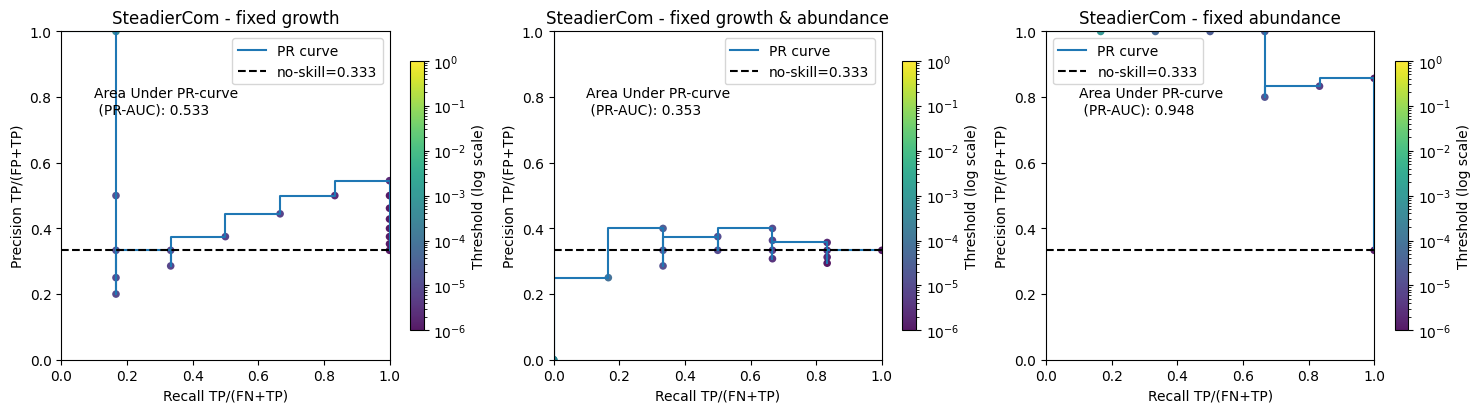

In [44]:


names = simulation_dict["receiver"]["steadiercom"].keys()
fig,axs = plt.subplots(1,3,figsize=(18,5))
for ax,name in zip(axs,names):
    simulated_res = simulation_dict["receiver"]["steadiercom"][name]
    diagnostic.plot_diagnostic_curve(simulated_res,
                                     signal_exp,
                                     PR_or_ROC="PR", 
                                     exp_thresh=0.5,
                                     receiver_or_donor="receiver",
                                     metric="frequency*mass_rate",
                                     met_column="compound",
                                     agg_method="sum",
                                     ax=ax,title="",
                                     plot_cbar=True, 
                                     verbose=True)
    
    ax.set_title(name)

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data


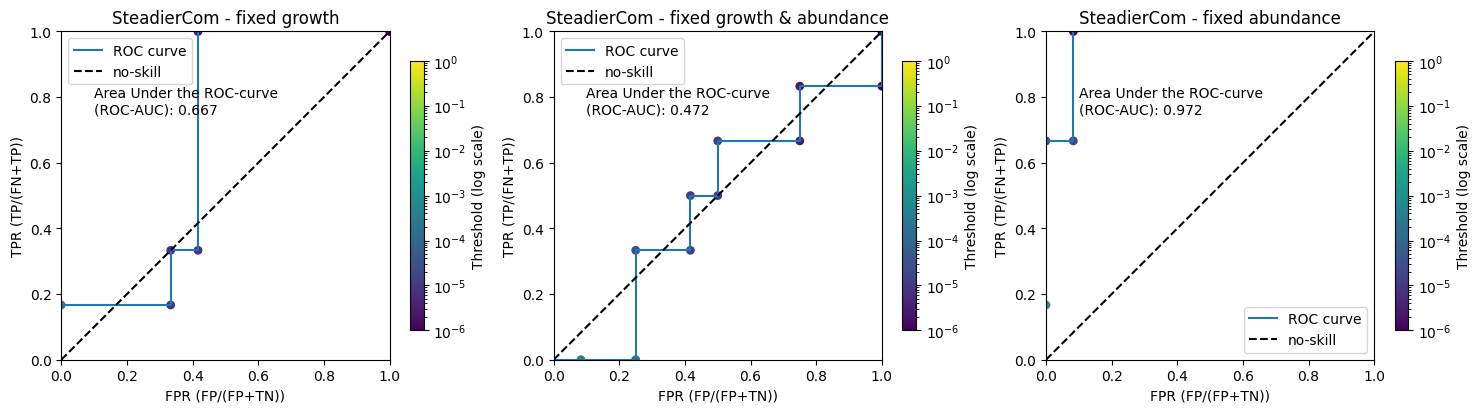

In [56]:


names = simulation_dict["receiver"]["steadiercom"].keys()
fig,axs = plt.subplots(1,3,figsize=(18,5))
for ax,name in zip(axs,names):
    simulated_res = simulation_dict["receiver"]["steadiercom"][name]
    diagnostic.plot_diagnostic_curve(simulated_res,
                                     signal_exp,
                                     PR_or_ROC="ROC", 
                                     exp_thresh=0.5,
                                     receiver_or_donor="receiver",
                                     metric="frequency*mass_rate",
                                     met_column="compound",
                                     agg_method="sum",
                                     ax=ax,title="",
                                     plot_cbar=True, 
                                     verbose=True)
    
    ax.set_title(name)

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data


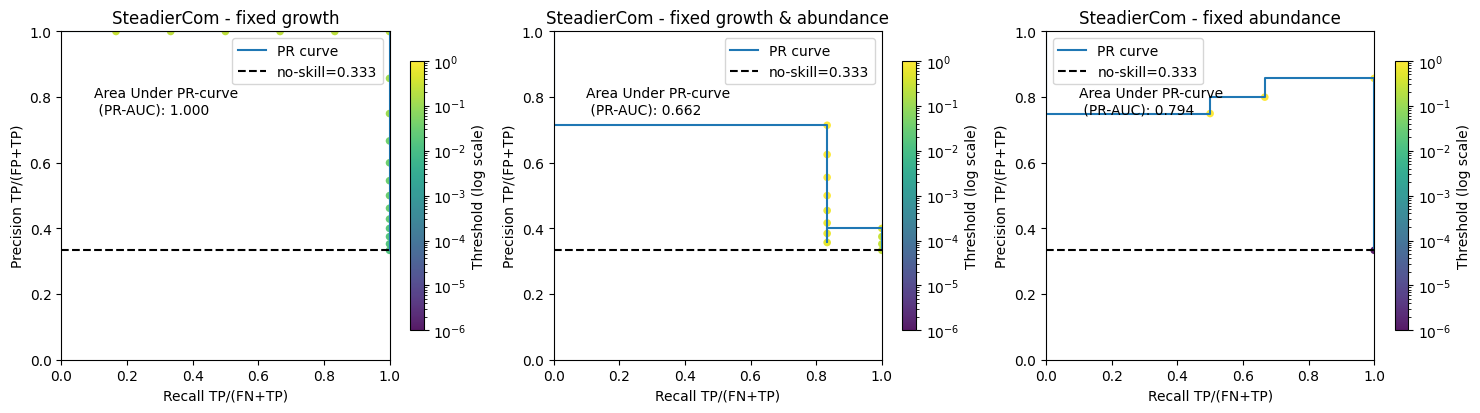

In [46]:


names = simulation_dict["receiver"]["steadiercom"].keys()
fig,axs = plt.subplots(1,3,figsize=(18,5))
for ax,name in zip(axs,names):
    simulated_res = simulation_dict["receiver"]["steadiercom"][name]
    diagnostic.plot_diagnostic_curve(simulated_res,
                                     signal_exp,
                                     PR_or_ROC="PR", 
                                     exp_thresh=0.5,
                                     receiver_or_donor="receiver",
                                     metric="frequency",
                                     met_column="compound",
                                     agg_method="sum",
                                     ax=ax,
                                     title="",
                                     plot_cbar=True,
                                     verbose=True)
    ax.set_title(name)

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data


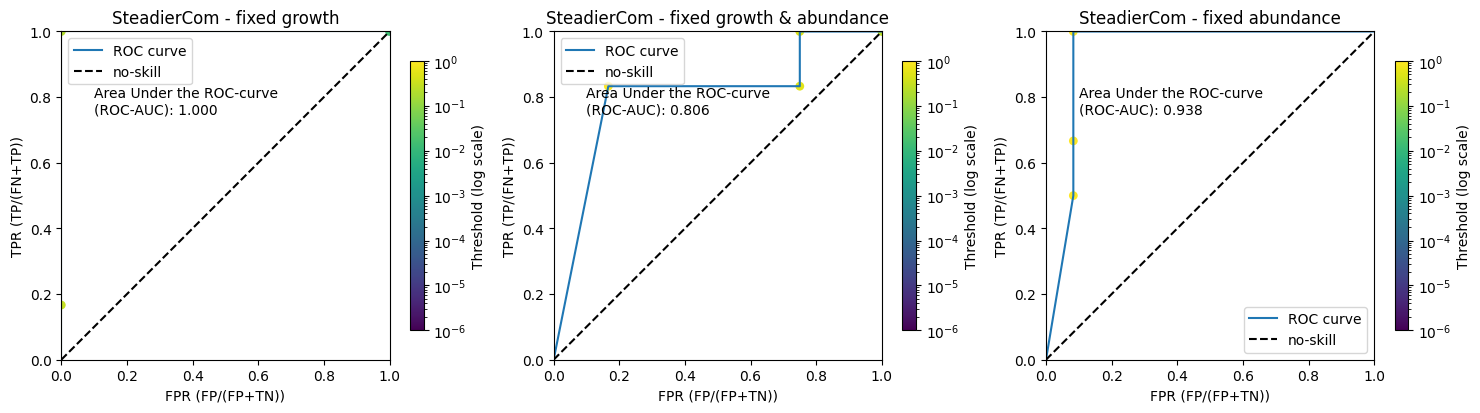

In [55]:


names = simulation_dict["receiver"]["steadiercom"].keys()
fig,axs = plt.subplots(1,3,figsize=(18,5))
for ax,name in zip(axs,names):
    simulated_res = simulation_dict["receiver"]["steadiercom"][name]
    diagnostic.plot_diagnostic_curve(simulated_res,
                                     signal_exp,
                                     PR_or_ROC="ROC", 
                                     exp_thresh=0.5,
                                     receiver_or_donor="receiver",
                                     metric="frequency",
                                     met_column="compound",
                                     agg_method="sum",
                                     ax=ax,
                                     title="",
                                     plot_cbar=True,
                                     verbose=True)
    ax.set_title(name)

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data


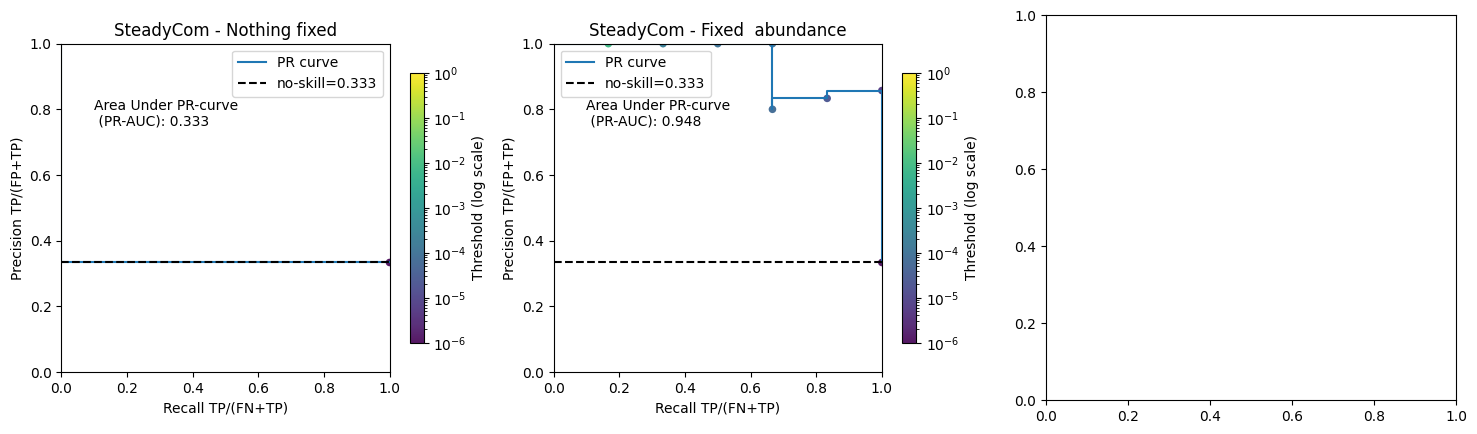

In [54]:


names = simulation_dict["receiver"]["steadycom"].keys()
fig,axs = plt.subplots(1,3,figsize=(18,5))
for ax,name in zip(axs,names):
    simulated_res = simulation_dict["receiver"]["steadycom"][name]
    diagnostic.plot_diagnostic_curve(simulated_res,
                                     signal_exp,
                                     PR_or_ROC="PR", 
                                     exp_thresh=0.5,
                                     receiver_or_donor="receiver",
                                     metric="rate?",
                                     met_column="compound",
                                     agg_method="sum",
                                     ax=ax,
                                     title="",
                                     plot_cbar=True,
                                     verbose=True)
    ax.set_title(name)